### Apriori

In [1]:
import pandas as pd

data = pd.read_csv('bank_prod_order.csv',encoding='gbk')
data.head()

,OrderNumber,CSR_ID,PROD
0,0,30924038,抵押贷
1,1,30924038,黄金1号
2,2,30924038,网银
3,2,30924038,想分就分
4,4,30924062,pos贷


In [2]:
baskets = data['PROD'].groupby(data['CSR_ID']).apply(list)
baskets.head()

CSR_ID
335380                      [加速积分]
337320                       [好享贷]
339311    [财务通, 好享贷, 基金, 手机银行, 网银]
351538                       [好享贷]
367537                   [好享贷, 网银]
Name: PROD, dtype: object

In [3]:
import sys
sys.path.append('./myscript')
from apriori import arules

rules = arules(baskets, min_support=0.02)
rules.head()

apriori imported!


,LHS,RHS,support,confidence,lift
0,(好享贷),(手机银行),0.145833,0.233853,0.956671
1,(手机银行),(好享贷),0.145833,0.596591,0.956671
2,(手机银行),(基金),0.026389,0.107955,1.653772
3,(基金),(手机银行),0.026389,0.404255,1.653772
4,(好享贷),(网银),0.422222,0.677060,0.953979


可以根据需要进行后续处理，例如按照confidence和lift过滤后，按support排序

In [4]:
conf = rules[(rules.confidence > 0.1) & (rules.lift > 1)]
conf.sort_values(by='support', ascending=False).head()

,LHS,RHS,support,confidence,lift
10,(网银),(手机银行),0.2000,0.281800,1.152820
11,(手机银行),(网银),0.2000,0.818182,1.152820
114,(手机银行),"(网银, 好享贷)",0.1125,0.460227,1.090012
117,"(好享贷, 手机银行)",(网银),0.1125,0.771429,1.086944
112,(网银),"(好享贷, 手机银行)",0.1125,0.158513,1.086944


如果有必要，我们也可以通过图形看一下规则在支持度、置信度和提升度上的分布情况

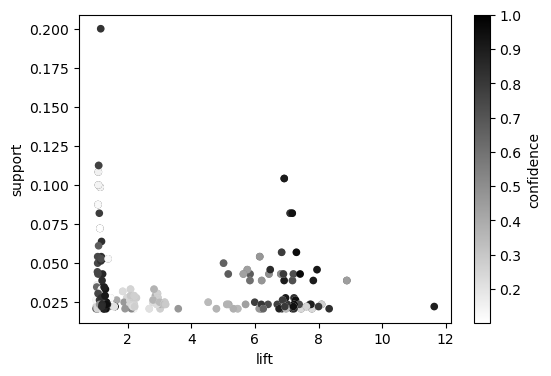

In [5]:
import matplotlib.pyplot as plt
%matplotlib inline

ax = plt.subplot()
ax.set_xlabel('lift')
conf.plot.scatter(x="lift", y="support",c="confidence",cmap='binary',
                  figsize=(6,4), ax=ax)

plt.show()

### FP_growth

`pip install Orange3-Associate` first!

[参考文档](https://orange3-associate.readthedocs.io/en/latest/scripting.html)

In [6]:
mapping = data['PROD'].drop_duplicates().to_dict()  # 生成{编号:产品}映射
inverse_mapping = {v:k for k, v in mapping.items()}     # 生成{产品:编号}映射

data['PROD'] = data['PROD'].replace(inverse_mapping)  # 将产品用编号替代
baskets = data['PROD'].groupby(data['CSR_ID']).apply(list)  
baskets.head()

CSR_ID
335380                  [29]
337320                  [16]
339311    [14, 16, 18, 9, 2]
351538                  [16]
367537               [16, 2]
Name: PROD, dtype: object

In [16]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules

# 1. 数据格式转换
te = TransactionEncoder()
te_ary = te.fit(baskets).transform(baskets)
df = pd.DataFrame(te_ary, columns=te.columns_)

# 2. 运行 FP-Growth
frequent_itemsets = fpgrowth(df, min_support=0.02, use_colnames=True)

# 3. 生成关联规则
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.1)

# 4. 整理结果，并还原产品名称
rules = rules.rename(columns={'antecedents': 'atecedent', 'consequents': 'consequent'})
pid_to_product = lambda fsets: tuple(mapping[int(fset)] for fset in fsets)
rules['atecedent'] = rules['atecedent'].apply(pid_to_product)
rules['consequent'] = rules['consequent'].apply(pid_to_product)

rules.head()

,atecedent,consequent,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,"(加速积分,)","(好享贷,)",0.077778,0.623611,0.044444,0.571429,0.916322,1.0,-0.004059,0.878241,-0.090099,0.067653,-0.138640,0.321349
1,"(加速积分,)","(网银,)",0.077778,0.709722,0.044444,0.571429,0.805144,1.0,-0.010756,0.677315,-0.207874,0.059813,-0.476418,0.317025
2,"(加速积分,)","(外汇保,)",0.077778,0.130556,0.029167,0.375000,2.872340,1.0,0.019012,1.391111,0.706827,0.162791,0.281150,0.299202
3,"(外汇保,)","(加速积分,)",0.130556,0.077778,0.029167,0.223404,2.872340,1.0,0.019012,1.187519,0.749734,0.162791,0.157908,0.299202
4,"(手机银行,)","(加速积分,)",0.244444,0.077778,0.027778,0.113636,1.461039,1.0,0.008765,1.040456,0.417647,0.094340,0.038883,0.235390


- atecedent (frozenset) – The LHS of the association rule.
- consequent (frozenset) – The RHS of the association rule.
- support (int) – Support as an absolute number of instances.
- confidence (float) – The confidence percent, calculated as: total_support / lhs_rupport.
- coverage (float) – Calculated as: lhs_support / n_examples
- strength (float) – Calculated as: rhs_support / lhs_examples
- lift (float) – Calculated as: n_examples * total_support / lhs_support / rhs_support
- leverage (float) – Calculated as: (total_support * n_examples - lhs_support * rhs_support) / n_examples**2